# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(paste your Streamlit URL)_

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [27]:
# Your data checks here
df.shape
df.value_counts()
df.duplicated().sum()
df.isna().sum()
df[df["decade"].isna()]
df.describe()
df["rating_year"].value_counts()
df["genres"].value_counts().describe()
df["year"].value_counts()
df[df["year"].isna()].groupby("title").count()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,year,decade,genres,rating_year
title,,,,,,,,,,,,
Heidi Fleiss: Hollywood Madam (1995),13,13,13,13,13,13,13,13,0,0,13,13
Land Before Time III: The Time of the Great Giving (1995) (V),6,6,6,6,6,6,6,6,0,0,6,6
Marlene Dietrich: Shadow and Light (1996),1,1,1,1,1,1,1,1,0,0,1,1
Two Friends (1986),1,1,1,1,1,1,1,1,0,0,1,1
unknown,9,9,9,9,9,9,9,9,0,0,9,9


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_

There are no duplicated rows, the 30 rows are missing a year and decade. The year and decade are already NaN so theres no need to change it. The genres column includes multiple genres per row using "|" as the delimeter. Some titles and genres are unknown.

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: I'm counting ratings. For movies that have several genres turn a row with multiple genres into different rows with one genre each.
- Why: I'm counting ratings since I want to know about each movie using their ratings. For genres I want to do what I'm doing so I can sort ratings by genre.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: I'm finding the average rating of each genre or each movie. For genres that have very little data we can disregard them. We can choose to only consider movies with at least 50 ratings.
- Why:  For genres with very little data the average rating would not be meaningful. For example a genre with only one 5 rating would have a higher average rating than a genre with over 10,000 ratings.

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: Every year is not backed by the same amount of data. Some have very little. I will drop the movies that have no release year.
- Why: There are only 5 movies with no release year, including unknown, making up only 30 rows. I will drop them since it's very few.

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: A movie's rating is the mean of all their ratings. It should have at least 50 ratings (≥), if there's a tie the winner should be decided by which movie has more ratings.
- Why: The mean rating would take into account all of the ratings for a movie. In the case of a tie, the movie with more ratings should win since it has more data supporting it.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

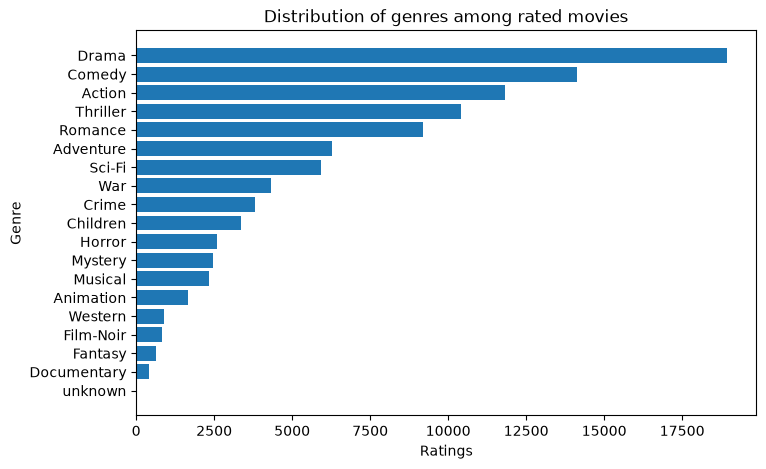

,genre,percent
18,unknown,0.007
6,Documentary,0.397
8,Fantasy,0.637
9,Film-Noir,0.814
17,Western,0.896
2,Animation,1.662
11,Musical,2.337
12,Mystery,2.470
10,Horror,2.590
3,Children,3.344


In [97]:
# Q1: your code here

genre_df = df.assign(genre=df['genres'].str.split('|').explode('genre'))
genre_count = pd.DataFrame(genre_df.groupby('genre')['rating'].count())
genre_count = genre_count.reset_index()
genre_count = genre_count.sort_values(by='rating', ascending=True)

fig, ax = plt.subplots(figsize=(8,5))

genre_count

bars = ax.barh(genre_count['genre'], genre_count['rating'])

ax.set_title('Distribution of genres among rated movies')
ax.set_xlabel('Ratings')
ax.set_ylabel('Genre')

plt.show()

genre_percent = genre_count.assign(rating=genre_count['rating']/genre_count['rating'].sum() * 100)
genre_percent.rename(columns={'rating' : 'percent'})

**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_

Drama, Comedy, Action, Thriller, and Romance dominate the genres. They make up over 50% of the ratings. Drama makes up about 19%, comedy 14%, action 12%, thriller 10%, and romance 9%. I counted the number of ratings each genre has.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

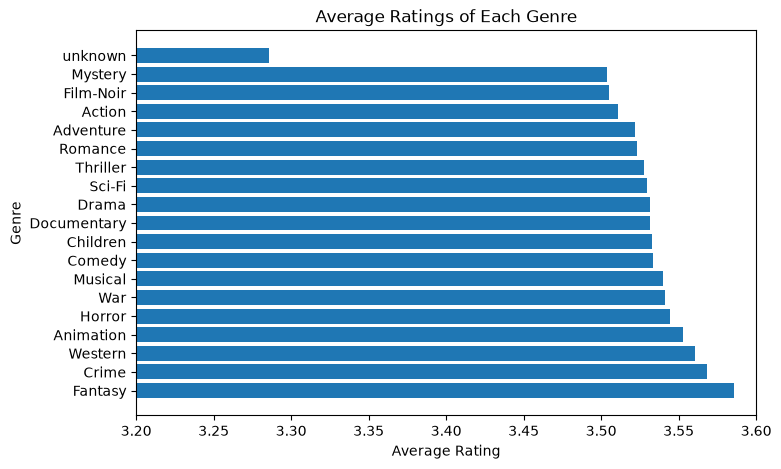

,genre,mean,count
8,Fantasy,3.585557,637
5,Crime,3.568008,3801
17,Western,3.560268,896
2,Animation,3.552948,1662
10,Horror,3.544402,2590
16,War,3.541503,4325
11,Musical,3.540009,2337
4,Comedy,3.533258,14132
3,Children,3.532895,3344
6,Documentary,3.531486,397


In [96]:
# Q2: your code here

genre_average_ratings = pd.DataFrame(genre_df.groupby('genre')['rating'].agg(['mean', 'count']))
genre_average_ratings = genre_average_ratings.reset_index()
genre_average_ratings = genre_average_ratings.sort_values(by='mean', ascending=False)

fig1, ax1 = plt.subplots(figsize=(8,5))

ax1.barh(genre_average_ratings['genre'], genre_average_ratings['mean'])
ax1.set_title('Average Ratings of Each Genre')
ax1.set_xlabel('Average Rating')
ax1.set_ylabel('Genre')
plt.xlim(3.2,3.6)

plt.show()

genre_average_ratings

**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_

The top genre is fantasy with an average of 3.585557 and 637 ratings. The bottom genre is unknown with a an average of 3.285714 and 7 ratings. The bottom known genre is mystery with an average of 3.504049 and 2,470 ratings.

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

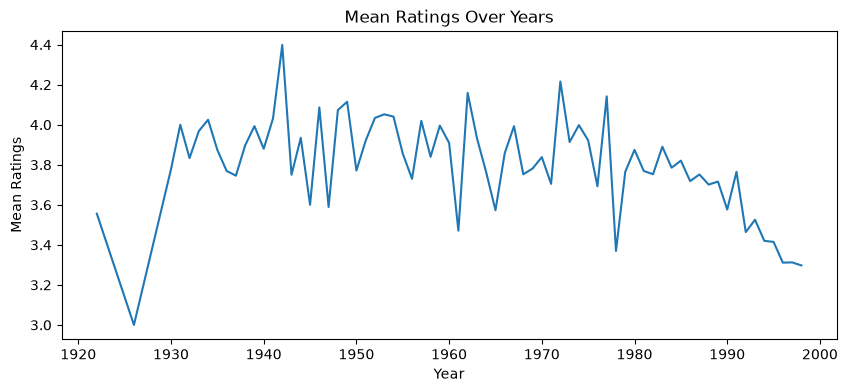

,year,count,mean
70,1998.0,851,3.297297
69,1997.0,15384,3.312467
68,1996.0,18744,3.311086
67,1995.0,12389,3.414642
66,1994.0,9034,3.420080
...,...,...,...
4,1932.0,12,3.833333
3,1931.0,44,4.000000
2,1930.0,18,3.777778
1,1926.0,2,3.000000


In [73]:
# Q3: your code here

year_count = pd.DataFrame(df.groupby('year')['rating'].agg(['count', 'mean']))
year_count = year_count.reset_index()
year_count = year_count.sort_values(by='year', ascending=False)

plt.figure(figsize=(10,4))
plt.plot(year_count['year'], year_count['mean'])

plt.title("Mean Ratings Over Years")
plt.xlabel("Year")
plt.ylabel("Mean Ratings")

plt.show()

year_count



**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_

Aside from the first decade, it seems the mean ratings spiked in the beginning of each decade and had dips throughout the middle of each decade. After 1980 the ratings started going downhill.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

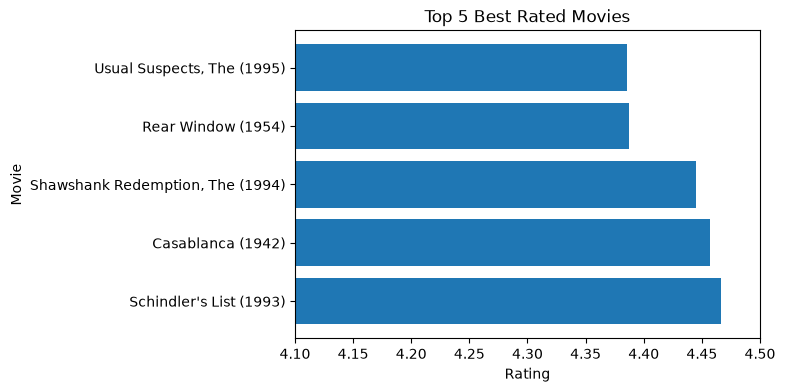

,title,count,mean
1281,Schindler's List (1993),298,4.466443
273,Casablanca (1942),243,4.456790
1317,"Shawshank Redemption, The (1994)",283,4.445230
1215,Rear Window (1954),209,4.387560
1572,"Usual Suspects, The (1995)",267,4.385768


In [110]:
# Q4: your code here
best_rated_movies = pd.DataFrame(df.groupby('title')['rating'].agg(['count', 'mean']))
best_rated_movies = best_rated_movies.reset_index()
best_rated_movies = best_rated_movies.sort_values(by='mean', ascending=False)
best_rated_movies = best_rated_movies[best_rated_movies['count'] >= 150]

fig2, ax2 = plt.subplots(figsize=(6,4))

ax2.barh(best_rated_movies.head(5)['title'], best_rated_movies.head(5)['mean'])
ax2.set_title("Top 5 Best Rated Movies")
ax2.set_xlabel("Rating")
ax2.set_ylabel("Movie")

ax2.set_xlim(4.1, 4.5)

plt.show()

best_rated_movies.head(5)

**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_

With a floor of 50 Casablanca (1942) was number 4 and Schindler's List (1993) was number 2. After the floor went up to 150, Close Shave,A (1995), Wrong Trousers,The(1993), Wallace & Gromit: The Best of Aardman Animation (1996) were dropped. Usual Suspects,The (1995), Shawshank Redemption,The (1994), and Rear Window (1954) moved in. Casablanca (1942) was moved up to number 2 and Schindler's List (1993) was moved up to number 1. With the floor of 50, three of the movies had less than 120 ratings while two of them had over 200. After the floor went up they all had more than 200 ratings. Small samples are less supporting of their conclusions compared to larger samples since they are more easily influenced.

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked: I am trying to make a dashboard that shows different statistics using the movie_ratings.csv file in the data folder. I want you to answer these four questions with a chart.

Question 1 — Genre Breakdown: What's the distribution of genres among the movies that were rated? (Movies can have multiple genres — have the AI explain how it handled that before it counts anything.)

Question 2 — Genre Satisfaction: Which genres have the highest average rating? Which have the lowest?

Question 3 — Ratings Over Time: How has the mean rating changed across movie release years?

Question 4 — Best Movies, With a Floor: What are the top 5 best-rated movies, once you only count movies with at least 50 ratings? What changes if you raise that floor to 150?
- AI's first attempt: Created the plan to build the dashboard and then I had it build it. Answered the four questions and made a graph for each.
- What I changed (or accepted without checking): The four graphs were made, horizontal bar graphs for the first 2 questions, a line graph for the third, and another horizontal bar graph for the fourth. It made a button to toggle between have minimum 50 and 150 ratings for question 4.

**Prompt 2**
- What I asked: Can you make a slider for the minimum number of ratings to change it anywhere between 50 and 150.
- AI's first attempt: Nothing because I ran out of credits.
- What I changed (or accepted without checking):

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: Among 1,682 rated movies, Drama is the most common genre (725 movies). Summing the bars gives 2,893 genre assignments (more than 1,682 movies).
- I say: Drama, Comedy, Action, Thriller, and Romance dominate the genres. They make up over 50% of the ratings. Drama makes up about 19%, comedy 14%, action 12%, thriller 10%, and romance 9%. I counted the number of ratings each genre has.
- Same? (yes / partly / no): partly
- If different, why?
Dashboard just gives the top genre while I give the top 5 and how much of the ratings they make up.

**Q2**
- Dashboard says: Each rating of a multi-genre movie is included in every one of that movie's genres, then we take the mean rating. Film-Noir has the highest average (3.92); unknown has the lowest (3.20).
- I say: The top genre is fantasy with an average of 3.585557 and 637 ratings. The bottom genre is unknown with a an average of 3.285714 and 7 ratings. The bottom known genre is mystery with an average of 3.504049 and 2,470 ratings.
- Same? (yes / partly / no): no
- If different, why?
The dashboard shows that each genre has more ratings that they do in the dataframe I was working with, this must have influenced the average ratings.

**Q3**
- Dashboard says: Mean rating is grouped by movie release year (year), not when the user rated it. Older titles in this set tend to sit higher: the peak year is 1942 (4.40); the lowest is 1926 (3.00). Hover a point to see how many ratings that year contributed — early years are sparse.
- I say: Aside from the first decade, it seems the mean ratings spiked in the beginning of each decade and had dips throughout the middle of each decade. After 1980 the ratings started going downhill.
- Same? (yes / partly / no): yes
- If different, why?
The dashboard says older movies in general have higher ratings, while I am saying the movies at the beginning of each decade have higher ratings. We have different interpretations of the data.

**Q4**
- Dashboard says: A movie with one 5-star rating would otherwise dominate a leaderboard. We keep only titles with at least N ratings, then rank by mean rating.

Floor of 50: Close Shave, A (1995) (4.49, n=112); Schindler's List (1993) (4.47, n=298); Wrong Trousers, The (1993) (4.47, n=118); Casablanca (1942) (4.46, n=243); Wallace & Gromit: The Best of Aardman Animation (1996) (4.45, n=67).

Floor of 150: Schindler's List (1993) (4.47, n=298); Casablanca (1942) (4.46, n=243); Shawshank Redemption, The (1994) (4.45, n=283); Rear Window (1954) (4.39, n=209); Usual Suspects, The (1995) (4.39, n=267).

Raising the floor from 50 to 150, these titles drop out: Close Shave, A (1995), Wallace & Gromit: The Best of Aardman Animation (1996), Wrong Trousers, The (1993); enter the top 5: Rear Window (1954), Shawshank Redemption, The (1994), Usual Suspects, The (1995).
- I say: With a floor of 50 Casablanca (1942) was number 4 and Schindler's List (1993) was number 2. After the floor went up to 150, Close Shave,A (1995), Wrong Trousers,The(1993), Wallace & Gromit: The Best of Aardman Animation (1996) were dropped. Usual Suspects,The (1995), Shawshank Redemption,The (1994), and Rear Window (1954) moved in. Casablanca (1942) was moved up to number 2 and Schindler's List (1993) was moved up to number 1. With the floor of 50, three of the movies had less than 120 ratings while two of them had over 200. After the floor went up they all had more than 200 ratings. Small samples are less supporting of their conclusions compared to larger samples since they are more easily influenced.
- Same? (yes / partly / no): yes
- If different, why?

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

For Q3 our graphs ended up exactly the same. We both used a line graph and it showed the same trend. We both took the average ratings of the movies from each year. One difference is AI used size to count the ratings for each year while I used count.

For Q4 me and the AI got the same result. One thing I noticed was that the AI used df.nlargest(5, "mean_rating") to return the top 5 movies. Meanwhile I sorted the dataframe by meanratings in descending order and returned df.head(5).

## 3.3 Chart choices

**Q1**
- Chart the dashboard used: Horizontal bar graph
- Chart I used: Horizontal bar graph
- Which communicates the answer better, and why?

Horizontal bar graph works better here since the categories are genres which can be long and would not fit on the x axis. They fit better on the y axis.

**Q2**
- Chart the dashboard used: Horizontal bar graph
- Chart I used: Horizontal bar graph
- Which communicates the answer better, and why?

Same answer for question 1.

**Q3**
- Chart the dashboard used: Line graph
- Chart I used: Line graph
- Which communicates the answer better, and why?

With the line graph you can see clearly how the mean ratings have changed over the years. You could also see it with a bar graph or histogram but the change wouldn't be as clear.

**Q4**
- Chart the dashboard used: Horizontal bar graph
- Chart I used: Horizontal bar graph
- Which communicates the answer better, and why?

Same answer as Q1 but instead of genres it's movie titles.

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

The  data in my graphs are sorted, the labels are readable, and the axes are honest. They do not show how much data is behind each number though.

In [143]:
user_ratings = pd.DataFrame(df.groupby('user_id')['rating'].size())
user_ratings = user_ratings.reset_index()
user_ratings = user_ratings.sort_values(by='rating', ascending=False)
user_ratings

year_ratings = pd.DataFrame(df.groupby('year')['user_id'].nunique())
year_ratings = year_ratings.reset_index()

year_ratings = year_ratings.rename(columns={'user_id' : 'user_count'})
year_ratings = year_ratings.sort_values(by='user_count', ascending=False)
year_ratings

,year,user_count
68,1996.0,935
69,1997.0,917
67,1995.0,791
66,1994.0,688
49,1977.0,619
...,...,...
8,1936.0,35
15,1943.0,22
2,1930.0,18
4,1932.0,12


## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.


**✏️ Your answers:** _(label each one with its number)_

1.) There are many more different users leaving ratings on movies in the more recent years, while in the older years they have many less ratings.

5.) A misleading conclusion they could draw is that fantasy needs to be greenlit since it is the number 1 rated genre. Although it is there are not as many ratings backing it up (only 637) while several others have other 2,000 ratings and have an average rating thats close to fantasy's.

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better): The scaling of some graphs made it hard to see the difference in ratings. For Q4 all the bars look the same length, I changed the scale of the x axis so the bars would not all be the same and the difference could be seen.

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right): AI included the amount of evidence backing up each point in it's graphs.

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?

This week I was driving and the other week AI was driving.

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week